# Digit Recognizer no Kaggle

Classificação supervisionada de dígitos manuscritos. O notebook compara uma referência linear com um modelo que descreve os traços da imagem e avalia sua sensibilidade a deslocamentos.


Abra o notebook na raiz do repositório e execute as células em ordem. O notebook encontra os CSVs em `data/`, inclusive quando a extração cria pastas chamadas `train.csv` e `test.csv`.

O kernel do Colab roda em uma máquina remota. Se ela não tiver uma cópia do repositório, envie `train.csv` e `test.csv` pelo painel Arquivos para o diretório de trabalho do kernel. Se estiverem em outro diretório remoto, indique o caminho em `DATA_DIR` na próxima célula. Os modelos usam CPU mesmo em um runtime com GPU.

Se precisar baixar os dois arquivos, acesse a [aba Data da competição](https://www.kaggle.com/competitions/digit-recognizer/data) após aceitar as [regras](https://www.kaggle.com/competitions/digit-recognizer/rules). Em um Kaggle Notebook, adicione os dados da competição como entrada.

Se faltar alguma biblioteca, execute `%pip install numpy pandas scikit-learn opencv-python-headless matplotlib threadpoolctl` em uma célula e reinicie o kernel se necessário. A última célula grava `submission.csv` no diretório de trabalho do kernel, ou em `/kaggle/working` no Kaggle.

In [1]:
from pathlib import Path
from time import perf_counter

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from threadpoolctl import threadpool_limits

SEED = 42
THREADS = 4
CLASSES = np.arange(10)
PIXELS = [f"pixel{i}" for i in range(784)]

# Use Path("/caminho/para/os/CSVs") se os arquivos estiverem em outro diretório.
DATA_DIR = None
candidates = [DATA_DIR] if DATA_DIR is not None else [
    Path.cwd() / "data",
    Path.cwd(),
    Path("/kaggle/input/competitions/digit-recognizer"),
    Path("/kaggle/input/digit-recognizer"),
]


def csv_path(directory, filename):
    path = directory / filename
    return path / filename if path.is_dir() else path


for directory in candidates:
    train_path = csv_path(directory, "train.csv")
    test_path = csv_path(directory, "test.csv")
    if train_path.is_file() and test_path.is_file():
        break
else:
    searched = ", ".join(str(path) for path in candidates)
    raise FileNotFoundError(
        f"Coloque train.csv e test.csv no mesmo diretório de dados ou ajuste DATA_DIR. "
        f"Diretórios verificados: {searched}."
    )

OUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").is_dir() else Path.cwd()

print(f"NumPy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | OpenCV {cv2.__version__}")

NumPy 2.3.5 | pandas 2.2.3 | scikit-learn 1.8.0 | OpenCV 4.11.0


## Dados e divisão estratificada

Cada imagem usa 784 intensidades em ordem de linha. A divisão reserva 20% dos exemplos de cada classe, aproximadamente, para validação. O arquivo de teste só entra no fim, depois da escolha do modelo.

Treino: 33,600 | Validação: 8,400


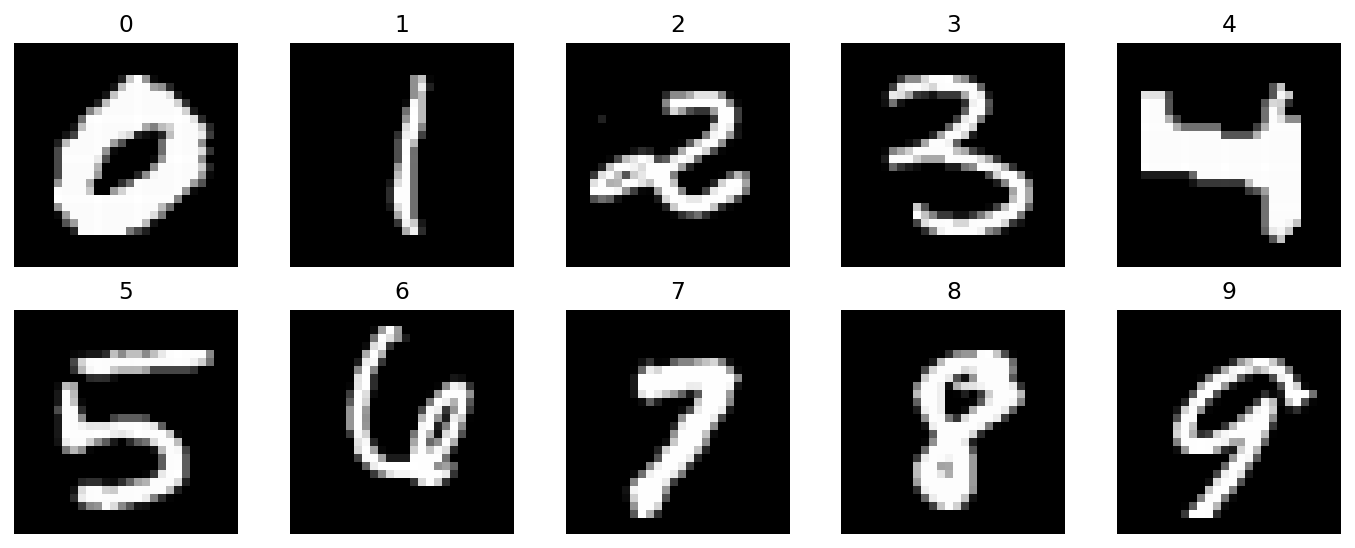

In [2]:
def read_digits(path, labeled, expected_rows):
    expected_columns = ["label", *PIXELS] if labeled else PIXELS
    frame = pd.read_csv(path, dtype=np.int16)
    if frame.columns.tolist() != expected_columns or len(frame) != expected_rows:
        raise ValueError(f"Esquema ou tamanho inesperado em {path.name}.")
    values = frame.loc[:, PIXELS].to_numpy()
    if values.min() < 0 or values.max() > 255:
        raise ValueError(f"Intensidade fora do intervalo 0–255 em {path.name}.")
    images = np.ascontiguousarray(values.reshape(-1, 28, 28), dtype=np.uint8)
    if not labeled:
        return images
    labels = frame["label"].to_numpy()
    if not np.array_equal(np.unique(labels), CLASSES):
        raise ValueError("O treino deve conter as classes inteiras de 0 a 9.")
    return images, labels


images, labels = read_digits(train_path, labeled=True, expected_rows=42000)
indices = np.arange(len(labels))
fit_ids, val_ids = train_test_split(
    indices, test_size=0.20, stratify=labels, random_state=SEED
)
x_fit, y_fit = images[fit_ids], labels[fit_ids]
x_val, y_val = images[val_ids], labels[val_ids]

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for digit, ax in zip(CLASSES, axes.flat):
    ax.imshow(x_fit[np.flatnonzero(y_fit == digit)[0]], cmap="gray", vmin=0, vmax=255)
    ax.set_title(str(digit))
    ax.axis("off")
plt.tight_layout()
plt.show()
print(f"Treino: {len(fit_ids):,} | Validação: {len(val_ids):,}")

## Pixels, traços e estabilidade a deslocamentos

A regressão logística recebe pixels divididos por 255. O HOG calcula gradientes locais, distribui suas orientações em histogramas e normaliza blocos de células vizinhas. A SVM com kernel radial recebe o vetor HOG.

A terceira variante usa o mesmo modelo HOG e SVM para inferir na imagem original e em quatro versões deslocadas em um pixel. A média combina os escores de decisão por classe de cada versão. Os escores servem para ordenar as classes e não são probabilidades.

In [3]:
hog = cv2.HOGDescriptor((28, 28), (14, 14), (7, 7), (7, 7), 9)
TTA_SHIFTS = ((-1, 0), (1, 0), (0, -1), (0, 1))


def normalized_pixels(batch):
    return batch.reshape(-1, 784).astype(np.float32) / 255


def hog_vectors(batch):
    features = np.empty((len(batch), hog.getDescriptorSize()), dtype=np.float32)
    for row, image in enumerate(batch):
        features[row] = hog.compute(image).ravel()
    return features


def shift_images(batch, dx, dy):
    height, width = batch.shape[1:]
    shifted = np.zeros_like(batch)
    y_start, y_end = max(0, -dy), min(height, height - dy)
    x_start, x_end = max(0, -dx), min(width, width - dx)
    shifted[:, y_start + dy:y_end + dy, x_start + dx:x_end + dx] = (
        batch[:, y_start:y_end, x_start:x_end]
    )
    return shifted


def logistic_model():
    return LogisticRegression(C=1, max_iter=600, solver="lbfgs")


def svm_model():
    return SVC(C=10, gamma="scale", kernel="rbf", cache_size=512, break_ties=True)


def svm_labels(model, scores):
    return model.classes_[np.argmax(scores, axis=1)]


def averaged_scores(model, batch, original_scores):
    scores = original_scores.copy()
    for dx, dy in TTA_SHIFTS:
        scores += model.decision_function(hog_vectors(shift_images(batch, dx, dy)))
    return scores / (1 + len(TTA_SHIFTS))

## Comparação no mesmo conjunto de validação

A métrica principal é a proporção de acertos nas imagens originais. A segunda coluna usa as mesmas imagens deslocadas dois pixels para a direita e dois para cima, com preenchimento zero. Em caso de empate na métrica principal, prevalece a acurácia sob deslocamento. Se o empate persistir, prevalece a variante mais simples na ordem da tabela.

                             Validação original  Validação deslocada
Regressão logística                      91.32%               42.96%
HOG + SVM                                99.18%               93.10%
HOG + SVM com deslocamentos              99.21%               92.76%
Modelo escolhido: HOG + SVM com deslocamentos | Tempo da comparação: 51.6 s


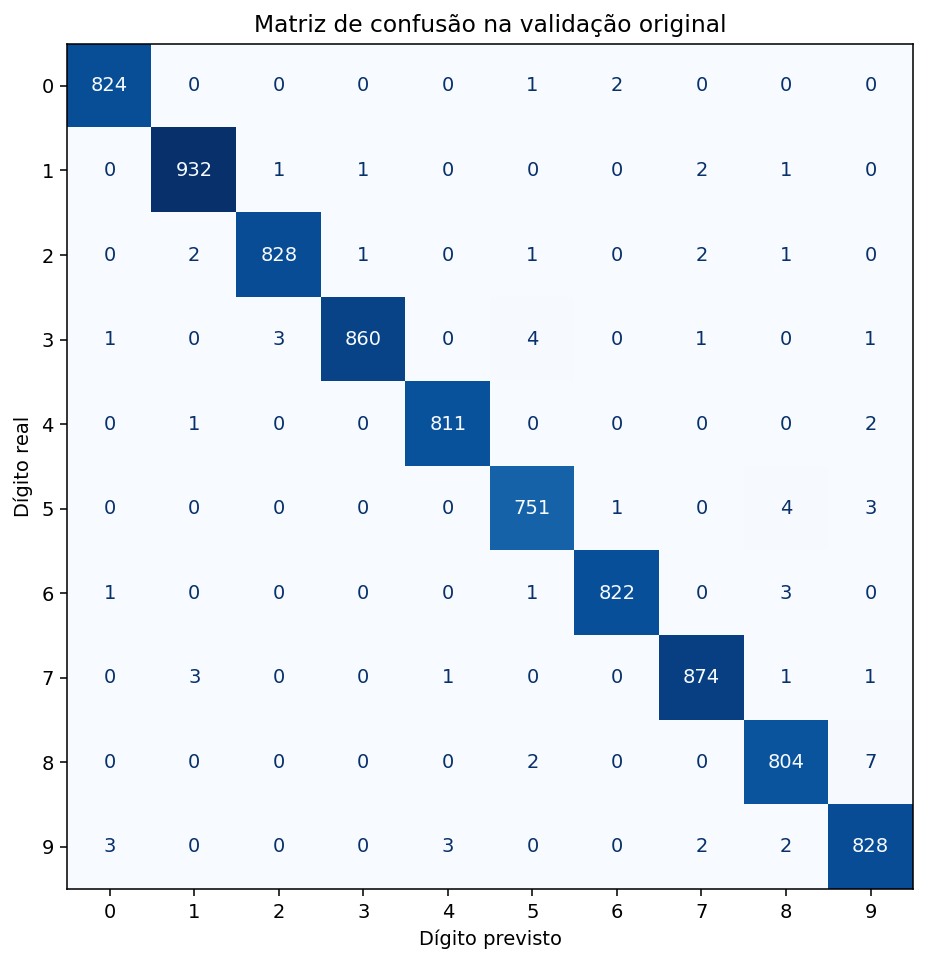

In [4]:
started = perf_counter()
shifted_val = shift_images(x_val, dx=2, dy=-2)
with threadpool_limits(limits=THREADS):
    baseline = logistic_model().fit(normalized_pixels(x_fit), y_fit)
    raw_predictions = (
        baseline.predict(normalized_pixels(x_val)),
        baseline.predict(normalized_pixels(shifted_val)),
    )

    svm = svm_model().fit(hog_vectors(x_fit), y_fit)
    clean_scores = svm.decision_function(hog_vectors(x_val))
    shifted_scores = svm.decision_function(hog_vectors(shifted_val))
    hog_predictions = (svm_labels(svm, clean_scores), svm_labels(svm, shifted_scores))
    tta_predictions = (
        svm_labels(svm, averaged_scores(svm, x_val, clean_scores)),
        svm_labels(svm, averaged_scores(svm, shifted_val, shifted_scores)),
    )

predictions = {
    "Regressão logística": raw_predictions,
    "HOG + SVM": hog_predictions,
    "HOG + SVM com deslocamentos": tta_predictions,
}
comparison = pd.DataFrame.from_dict(
    {
        name: {
            "Validação original": accuracy_score(y_val, clean),
            "Validação deslocada": accuracy_score(y_val, shifted),
        }
        for name, (clean, shifted) in predictions.items()
    },
    orient="index",
)
winner = max(predictions, key=lambda name: tuple(comparison.loc[name]))
print(comparison.to_string(float_format=lambda x: f"{x:.2%}"))
print(f"Modelo escolhido: {winner} | Tempo da comparação: {perf_counter() - started:.1f} s")

clean_prediction = predictions[winner][0]
matrix = confusion_matrix(y_val, clean_prediction, labels=CLASSES)
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(matrix, display_labels=CLASSES).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set(xlabel="Dígito previsto", ylabel="Dígito real", title="Matriz de confusão na validação original")
plt.tight_layout()
plt.show()

## Geração do arquivo para o Kaggle

Com a variante escolhida, treine novamente com os 42 mil exemplos rotulados. Gere previsões na ordem de `test.csv` e numere as imagens de 1 a 28.000 na coluna `ImageId`. A acurácia do teste é calculada pelo Kaggle após o envio.

In [5]:
started = perf_counter()
test_images = read_digits(test_path, labeled=False, expected_rows=28000)

with threadpool_limits(limits=THREADS):
    if winner == "Regressão logística":
        final_model = logistic_model().fit(normalized_pixels(images), labels)
        test_predictions = final_model.predict(normalized_pixels(test_images))
    else:
        final_model = svm_model().fit(hog_vectors(images), labels)
        test_scores = final_model.decision_function(hog_vectors(test_images))
        if winner == "HOG + SVM com deslocamentos":
            test_scores = averaged_scores(final_model, test_images, test_scores)
        test_predictions = svm_labels(final_model, test_scores)

submission = pd.DataFrame({
    "ImageId": np.arange(1, len(test_images) + 1),
    "Label": test_predictions.astype(int),
})
if len(submission) != 28000 or not submission["Label"].isin(CLASSES).all():
    raise ValueError("Submissão inválida: revise o total de linhas e o domínio de Label.")

destination = OUT_DIR / "submission.csv"
submission.to_csv(destination, index=False)
print(f"Arquivo: {destination.name} | Linhas de dados: {len(submission):,}")
print(submission.head().to_string(index=False))
print(f"Tempo do treino final e da geração do CSV: {perf_counter() - started:.1f} s")

Arquivo: submission.csv | Linhas de dados: 28,000
 ImageId  Label
       1      2
       2      0
       3      9
       4      0
       5      3
Tempo do treino final e da geração do CSV: 86.6 s
